In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# 1. 데이터 불러오기
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

In [4]:
df

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...,...
4172,4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


In [10]:
# 2. 입력/ 정답 분리 및 원 핫 인코딩
X=df.drop(['Sex','id'], axis=1, errors='ignore').values
y_raw=df['Sex'].values

encoder=LabelEncoder()
y_encoded=encoder.fit_transform(y_raw)
y=to_categorical(y_encoded)

# 3. 학습/테스트 데이터 분리
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y_encoded)

# 4. 데이터 정규화
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [11]:
# 5. 모델 생성

model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(8,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(3, activation="softmax"))


# 6. 모델 설정
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])


In [12]:
# 7. 모델 구조 출력
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 867 (3.39 KB)

 Trainable params: 867 (3.39 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# 8. 모델 학습

history = model.fit(X_train, y_train,
                    epochs=100,
                    batch_size=16,
                    validation_split=0.2, # 학습 데이터 중 20%는 학습 경과 검증으로 사용
                    verbose=0)


In [16]:
# 9. 테스트 데이터 예측

y_prob = model.predict(X_test) #scaling된  test data 입력
y_pred = np.argmax(y_prob, axis=1)  # 예측된 확률 중 가장 높은 클래스 (0,1,2) 선택
y_true = np.argmax(y_test, axis=1)  # 원핫 인코딩 된 정답(y_test)를 정수 (0,1,2)로 변환


# 10. 성능 평가
acc=accuracy_score(y_true, y_pred)
print("\nAccuracy:", acc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['F','I','M']))


27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Accuracy: 0.5490430622009569

Confusion Matrix:
[[140  22  99]
 [ 30 207  32]
 [134  60 112]]

Classification Report:
              precision    recall  f1-score   support

           F       0.46      0.54      0.50       261
           I       0.72      0.77      0.74       269
           M       0.46      0.37      0.41       306

    accuracy                           0.55       836
   macro avg       0.55      0.56      0.55       836
weighted avg       0.54      0.55      0.54       836



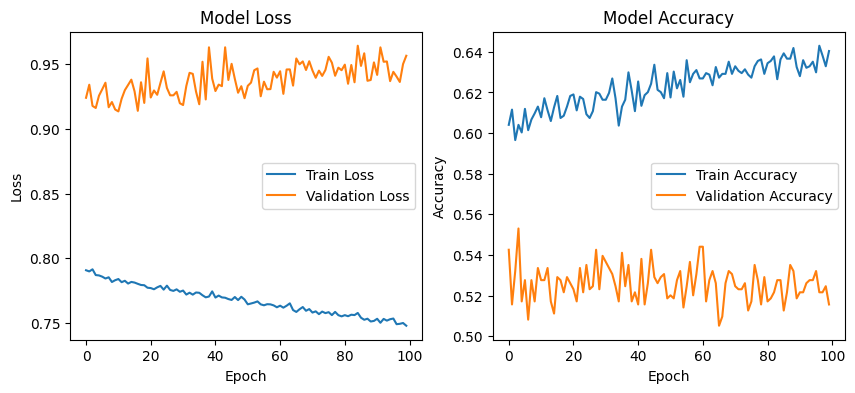

In [17]:
import matplotlib.pyplot as plt

# 손실(Loss) 시각화
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# 정확도(Accuracy) 시각화
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()